# 🔴 Red neuronal desde cero con NumPy — MNIST

**Objetivo:** clasificar dígitos escritos a mano (MNIST) con una red neuronal construida **a mano**: sin `.fit()`, sin autograd, sin Keras. Solo NumPy (cálculo) y Matplotlib (gráficos).

**La red en una línea:**

`imagen (784 píxeles)  →  Dense(128)  →  ReLU  →  Dense(10)  →  Softmax  →  probabilidad de cada dígito`

**Estructura del notebook**

| # | Sección | Qué hay |
|---|---------|---------|
| 1 | Carga y exploración | Dataset, ejemplos, shapes, preparación de datos |
| 2 | Implementación | Capa Dense, ReLU, Softmax, Cross-Entropy y backpropagation (con la matemática) |
| 3 | Entrenamiento | Loop de epochs, actualización de pesos |
| 4 | Evaluación | Curvas, accuracy en test, matriz de confusión, análisis de errores |
| 5 | Conclusiones | Qué entendí que antes no entendía |

# 1. Carga y exploración del dataset

**MNIST** tiene 70.000 imágenes de dígitos (0–9) en escala de grises de **28×28 píxeles**:
60.000 para entrenar y 10.000 para probar. Cada píxel es un entero entre 0 (negro) y 255 (blanco).

> Se importa `tensorflow.keras.datasets` **únicamente para descargar el dataset**. Toda la red (capas, activaciones, loss, backprop y entrenamiento) está escrita con NumPy.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import random
from tensorflow.keras.datasets import mnist   # solo para descargar los datos

np.random.seed(42)  #semilla numpy
random.seed(42)     #semilla python

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Entradas de entrenamiento:", X_train.shape)
print("Etiquetas de entrenamiento:", y_train.shape)
print("Entradas de prueba:", X_test.shape)
print("Etiquetas de prueba:", y_test.shape)
print("Rango de valores de los píxeles:", X_train.min(), "a", X_train.max())

Entradas de entrenamiento: (60000, 28, 28)
Etiquetas de entrenamiento: (60000,)
Entradas de prueba: (10000, 28, 28)
Etiquetas de prueba: (10000,)
Rango de valores de los píxeles: 0 a 255


Veamos un ejemplo de cada dígito y cuántas imágenes hay de cada clase (para saber si el dataset está balanceado):

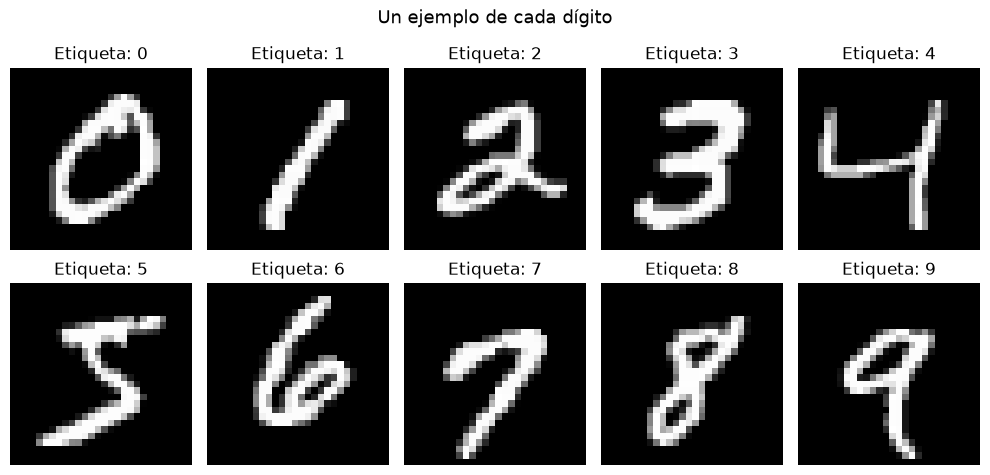

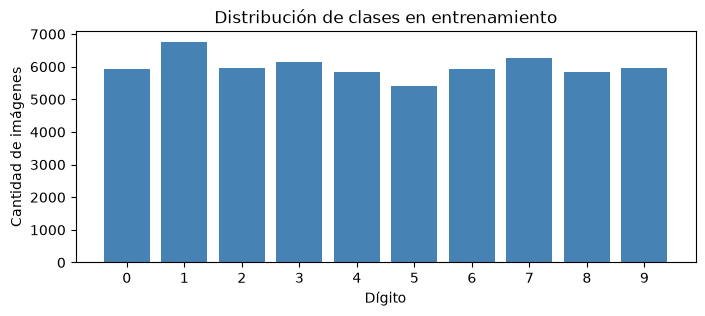

In [22]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digito, ax in enumerate(axes.flat):
    idx = np.where(y_train == digito)[0][0]          # primer ejemplo de ese dígito
    ax.imshow(X_train[idx], cmap="gray")
    ax.set_title(f"Etiqueta: {digito}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada dígito", fontsize=13)
plt.tight_layout()
plt.show()

conteo = np.bincount(y_train)
plt.figure(figsize=(8, 3))
plt.bar(range(10), conteo, color="steelblue")
plt.xticks(range(10))
plt.xlabel("Dígito"); plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de clases en entrenamiento")
plt.show()

### Preparación de los datos

La red recibe **vectores**, no imágenes. Hacemos tres cosas:

1. **Aplanar** cada imagen de `28×28` a un vector de `784` números (`reshape`).
2. **Normalizar** los píxeles de `[0, 255]` a `[0, 1]` (dividiendo por 255). Con entradas pequeñas y parecidas en escala, el entrenamiento es mucho más estable.
3. **Separar un set de validación** (10.000 imágenes de train). Lo uso para ver cómo evoluciona la red *durante* el entrenamiento sin "espiar" el set de test.**.

In [ ]:
#Calculo automatico de columnas, conversión a decimales y normalización.
X_train = X_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test  = X_test.reshape(-1, 784).astype(np.float32) / 255.0

#Nos aseguramos de tener en enteros.
y_train = y_train.astype(np.int64)
y_test  = y_test.astype(np.int64)

# Separar validación: últimas 10.000 imágenes de train (ya vienen mezcladas)
X_val, y_val = X_train[50000:], y_train[50000:]
X_train, y_train = X_train[:50000], y_train[:50000]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)

Entrenamiento: (50000, 784) (50000,)
Validación:    (10000, 784) (10000,)
Prueba:        (10000, 784) (10000,)


# 2. Implementación desde cero

## 2.1 Capa Densa (`Dense`)

Una capa densa conecta **cada entrada con cada neurona**. Para un lote de `n` muestras:

$$Z = X\,W + b$$

| Variable | Shape | Significado |
|----------|-------|-------------|
| `X` | `(n, entradas)` | datos que entran a la capa |
| `W` | `(entradas, neuronas)` | un peso por cada conexión |
| `b` | `(1, neuronas)` | un sesgo por neurona |
| `Z` | `(n, neuronas)` | salida (antes de activar) |

**Backward (regla de la cadena).** Si la capa siguiente me manda `dZ = ∂L/∂Z` (cuánto cambia la pérdida si cambia la salida), necesito tres cosas:

$$\frac{\partial L}{\partial W} = X^T\,dZ \qquad\qquad \frac{\partial L}{\partial b} = \sum_{\text{muestras}} dZ \qquad\qquad \frac{\partial L}{\partial X} = dZ\,W^T$$

- `dW = Xᵀ · dZ`: el peso `W[i,j]` conecta la entrada `i` con la neurona `j`; su efecto en la pérdida es "cuánto valía la entrada `i`" × "cuánto le importa a la pérdida la neurona `j`", sumado sobre todas las muestras.
- `db`: el sesgo se suma directo a `Z`, así que su gradiente es la suma de `dZ`.
- `dX = dZ · Wᵀ`: es lo que le **devuelvo a la capa anterior** para que ella siga la cadena hacia atrás.

> 🧩 Truco para no perderse con las shapes: cada gradiente tiene **la misma shape que lo que deriva** (`dW` es como `W`, `db` como `b`, `dX` como `X`). Las transposiciones salen solas de ahí.

**Inicialización (He):** `W ~ N(0, 2/entradas)`. Si los pesos son muy grandes o muy chicos, las señales explotan o se apagan a medida que cruzan capas. Con ReLU, esta escala mantiene la señal estable. La capa de salida usa una escala menor (`1/entradas`) para que al inicio las predicciones sean casi uniformes.

**Diseño:** `backward` solo **calcula y guarda** los gradientes (`dW`, `db`). El cambio de pesos lo hace `update` por separado. Así puedo inspeccionar y verificar los gradientes antes de usarlos.

In [ ]:
class Dense:
    def __init__(self, input_size, output_size, gain=2.0):
        # Un peso por conexión (entrada -> neurona). gain=2 es la inicialización He para Relu
        self.W = np.random.randn(input_size, output_size) * np.sqrt(gain / input_size)
        # Un sesgo por neurona
        self.b = np.zeros((1, output_size))
        # Se llenan en forward / backward
        self.input = None
        self.dW = None
        self.db = None

    def forward(self, X):
        self.input = X                    # guardo X: lo necesito en backward
        return X @ self.W + self.b        # Z = XW + b

    def backward(self, dZ):
        self.dW = self.input.T @ dZ                 # (entradas, n) @ (n, neuronas)
        self.db = np.sum(dZ, axis=0, keepdims=True) # suma sobre las muestras | Quita horizontal suma vertical
        dX = dZ @ self.W.T                          # gradiente hacia la capa anterior
        return dX

    def update(self, learning_rate):
        # Descenso de gradiente: moverse en contra del gradiente
        self.W -= learning_rate * self.dW
        self.b -= learning_rate * self.db

## 2.2 Activación ReLU

$$\text{ReLU}(z) = \max(0, z) \qquad\qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z \le 0 \end{cases}$$

Sin una activación no lineal, apilar capas densas equivale a **una sola** multiplicación de matrices: la red nunca podría aprender nada más complejo que una recta. ReLU introduce la no linealidad de la forma más simple: deja pasar lo positivo y apaga lo negativo.

En backward, ReLU funciona como una **compuerta**: el gradiente pasa intacto por las neuronas que estaban activas (`Z > 0`) y se corta en las apagadas.

In [5]:
class ReLU:
    def __init__(self):
        self.input = None

    def forward(self, Z):
        self.input = Z                   # guardo Z para saber qué neuronas estaban activas
        return np.maximum(0, Z)

    def backward(self, dA):
        mask = (self.input > 0)          # 1 donde Z > 0, 0 donde Z <= 0
        return dA * mask                 # la compuerta deja pasar solo a las activas

**Visualización de ReLU:** a la izquierda la función, a la derecha su derivada (la "compuerta" que se usa en backward).

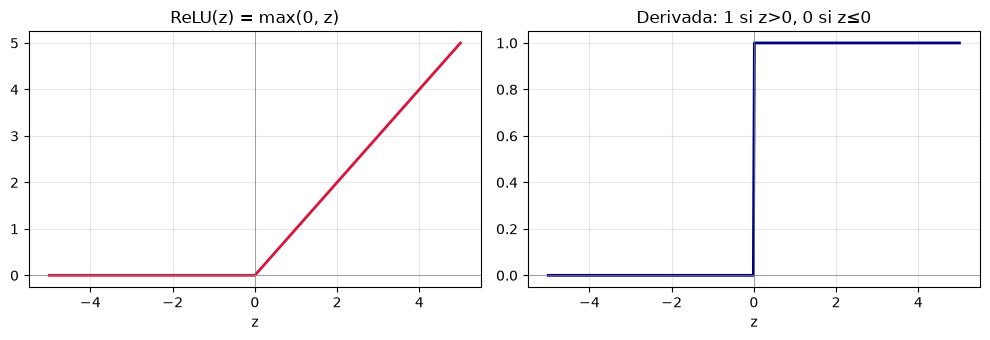

In [6]:
z = np.linspace(-5, 5, 400)
relu_demo = ReLU()
salida = relu_demo.forward(z)
derivada = relu_demo.backward(np.ones_like(z))   # backward con gradiente 1 = la derivada

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(z, salida, color="crimson", lw=2)
ax[0].set_title("ReLU(z) = max(0, z)")
ax[1].plot(z, derivada, color="navy", lw=2)
ax[1].set_title("Derivada: 1 si z>0, 0 si z≤0")
for a in ax:
    a.axhline(0, color="gray", lw=0.5); a.axvline(0, color="gray", lw=0.5)
    a.set_xlabel("z"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2.3 Softmax

La última capa produce 10 números cualquiera (los *logits*, pueden ser negativos o enormes). Softmax los convierte en **probabilidades**: positivas y que suman 1.

$$\text{softmax}(z_k) = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

**El drama matemático:** `e^1000` desborda (da `inf`) y `inf/inf` da `NaN`. La solución es restar el máximo de cada fila antes de exponenciar. El resultado **es el mismo** (el factor `e^{-max}` se cancela arriba y abajo) pero ahora el mayor exponente es `e⁰ = 1` y nunca desborda.

In [7]:
def softmax(Z):
    Z_estable = Z - np.max(Z, axis=1, keepdims=True)   # truco de estabilidad numérica
    exp_Z = np.exp(Z_estable)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

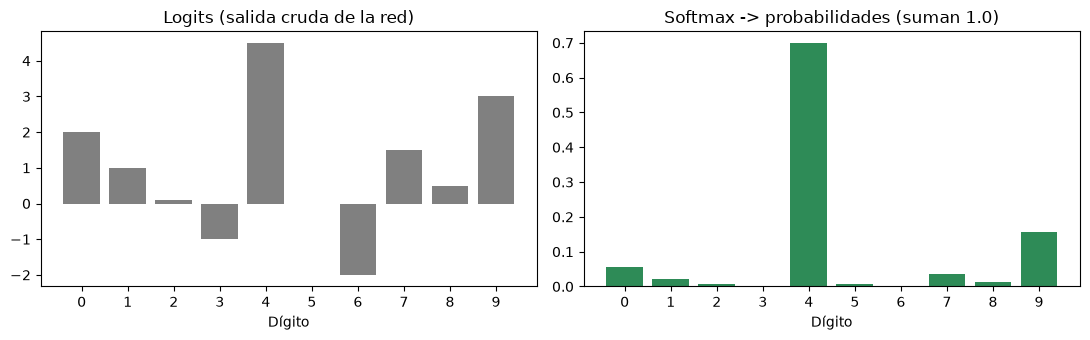

Softmax ingenuo  : [[nan nan nan]]
Softmax estable  : [[0.09003057 0.24472847 0.66524096]]


In [8]:
# --- Visualización 1: logits -> probabilidades ---
logits = np.array([[2.0, 1.0, 0.1, -1.0, 4.5, 0.0, -2.0, 1.5, 0.5, 3.0]])
probs_demo = softmax(logits)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(10), logits[0], color="gray")
ax[0].set_title("Logits (salida cruda de la red)")
ax[1].bar(range(10), probs_demo[0], color="seagreen")
ax[1].set_title(f"Softmax -> probabilidades (suman {probs_demo.sum():.1f})")
for a in ax:
    a.set_xticks(range(10)); a.set_xlabel("Dígito")
plt.tight_layout(); plt.show()

# --- Visualización 2: por qué hay que restar el máximo ---
grandes = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(all="ignore"):
    ingenuo = np.exp(grandes) / np.sum(np.exp(grandes), axis=1, keepdims=True)
print("Softmax ingenuo  :", ingenuo)
print("Softmax estable  :", softmax(grandes))

## 2.4 Pérdida Cross-Entropy

Mide **qué tan equivocada está la red**. Solo mira la probabilidad que la red le dio a la clase **correcta** `p_y`:

$$L = -\frac{1}{n}\sum_{i=1}^{n} \log\big(p_{i,\,y_i}\big)$$

- Si la red asigna `p = 1` a la clase correcta → `L = 0` (perfecto).
- Si asigna `p → 0` → `L → ∞` (castigo enorme por estar muy segura y equivocada).
- Una red que adivina al azar entre 10 clases da `p = 0.1` → `L = -log(0.1) = ln(10) ≈ 2.303`. **Este es el valor de partida esperado**: si tu pérdida se queda clavada en ~2.30, la red no está aprendiendo nada.

El `np.clip` evita `log(0)`.

In [ ]:
def cross_entropy(probs, y_true):
    n = probs.shape[0]
    probs_correctas = probs[np.arange(n), y_true]            # p que le dio a la clase correcta
    probs_correctas = np.clip(probs_correctas, 1e-12, 1.0)   # evita log(0) | Infinito negativo
    return -np.mean(np.log(probs_correctas))

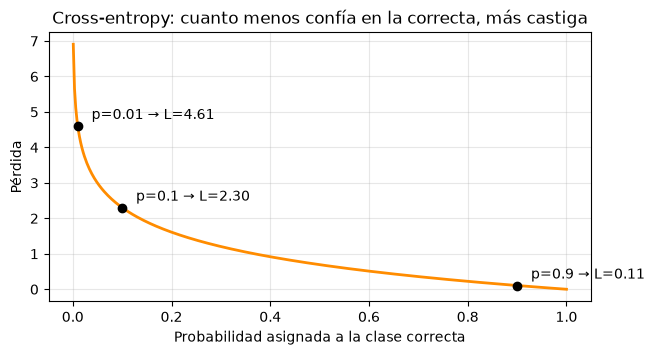

In [10]:
# Visualización: castigo = -log(p_correcta)
p = np.linspace(0.001, 1, 400)
plt.figure(figsize=(7, 3.5))
plt.plot(p, -np.log(p), color="darkorange", lw=2)
for pc in [0.9, 0.1, 0.01]:
    plt.scatter(pc, -np.log(pc), color="black", zorder=3)
    plt.annotate(f"p={pc} → L={-np.log(pc):.2f}", (pc, -np.log(pc)),
                 textcoords="offset points", xytext=(10, 5))
plt.xlabel("Probabilidad asignada a la clase correcta")
plt.ylabel("Pérdida")
plt.title("Cross-entropy: cuanto menos confía en la correcta, más castiga")
plt.grid(alpha=0.3); plt.show()

## 2.5 Backpropagation: la matemática paso a paso

La red es una cadena de funciones. Para una muestra o un lote de `n`:

$$X \xrightarrow{\;Z_1 = XW_1 + b_1\;} Z_1 \xrightarrow{\;A_1=\text{ReLU}(Z_1)\;} A_1 \xrightarrow{\;Z_2 = A_1W_2 + b_2\;} Z_2 \xrightarrow{\;P=\text{softmax}(Z_2)\;} P \xrightarrow{\;L\;} L$$

**Backprop = aplicar la regla de la cadena de derecha a izquierda**, reutilizando en cada paso el gradiente que llega del paso anterior. Voy desde la pérdida hasta la primera capa:

---

**Paso 1 — Softmax + Cross-Entropy juntos:** `∂L/∂Z₂`

Para una muestra con clase correcta `y`: `L = -z_y + log Σ_j e^{z_j}`. Derivando respecto de cada logit `z_k`:

$$\frac{\partial L}{\partial z_k} = p_k - \mathbb{1}[k = y] \quad\Longrightarrow\quad dZ_2 = \frac{P - Y_{\text{one-hot}}}{n}$$

Un resultado muy simple: **la probabilidad predicha menos lo que debería ser** (1 en la clase correcta, 0 en el resto). Se divide por `n` porque la pérdida es un promedio.
En código: copiar `P`, restar 1 en la posición de la clase correcta, dividir por `n`.

**Paso 2 — Capa de salida (`Dense 2`):**

$$dW_2 = A_1^T\,dZ_2 \qquad db_2 = \sum dZ_2 \qquad dA_1 = dZ_2\,W_2^T$$

**Paso 3 — ReLU:** el gradiente pasa solo por las neuronas activas

$$dZ_1 = dA_1 \odot \mathbb{1}[Z_1 > 0]$$

**Paso 4 — Capa oculta (`Dense 1`):**

$$dW_1 = X^T\,dZ_1 \qquad db_1 = \sum dZ_1$$

**Paso 5 — Actualización (descenso de gradiente):** con tasa de aprendizaje `η`

$$W \leftarrow W - \eta\,dW \qquad\qquad b \leftarrow b - \eta\,db$$

El gradiente apunta hacia donde la pérdida **sube**; restarlo nos mueve hacia donde **baja**.

In [11]:
def softmax_cross_entropy_backward(probs, y_true):
    # Paso 1: dZ2 = (P - Y_one_hot) / n
    n = probs.shape[0]
    dZ = probs.copy()
    dZ[np.arange(n), y_true] -= 1      # restar 1 en la clase correcta
    dZ /= n                            # la pérdida es un promedio
    return dZ

## 2.6 Armando la red

Junto las piezas en una clase. Cada método refleja un paso de la teoría: `forward` recorre la cadena de izquierda a derecha, `backward` de derecha a izquierda (pasos 1–4) y `update` aplica el paso 5.

In [ ]:
class RedNeuronal:
    # Arquitectura: 784 -> Dense(128) -> ReLU -> Dense(10) -> Softmax
    
    def __init__(self, n_entrada=784, n_oculta=128, n_salida=10):
        self.dense1 = Dense(n_entrada, n_oculta, gain=2.0)   # He (para ReLU)
        self.relu   = ReLU()
        self.dense2 = Dense(n_oculta, n_salida, gain=1.0)    # salida: pesos más chicos

    def forward(self, X):
        Z1 = self.dense1.forward(X)
        A1 = self.relu.forward(Z1)
        Z2 = self.dense2.forward(A1)
        return softmax(Z2)                                   # probabilidades

    def backward(self, probs, y_true):
        dZ2 = softmax_cross_entropy_backward(probs, y_true)  # paso 1
        dA1 = self.dense2.backward(dZ2)                      # paso 2
        dZ1 = self.relu.backward(dA1)                        # paso 3
        self.dense1.backward(dZ1)                            # paso 4

    def update(self, learning_rate):
        self.dense1.update(learning_rate)                    # paso 5
        self.dense2.update(learning_rate)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

## 2.7 ¿Mis gradientes están bien? Gradient checking

Derivar a mano es propenso a errores, y un gradiente mal calculado **no da error: simplemente la red no aprende**. Hay una forma de comprobarlo sin confiar en mi álgebra: la definición de derivada.

$$\frac{\partial L}{\partial w} \approx \frac{L(w+\varepsilon) - L(w-\varepsilon)}{2\varepsilon}$$

Muevo un peso un poquito hacia arriba y hacia abajo, mido cuánto cambia la pérdida y comparo con el gradiente que calculó mi backprop. Si coinciden (error relativo ≲ 1e-6), mi backprop es correcto.

In [13]:
def gradient_check(red, X, y, n_muestras=4, eps=1e-5):
    # Compara el gradiente de backprop con el gradiente numérico
    X = X.astype(np.float64)
    probs = red.forward(X)
    red.backward(probs, y)                        # gradientes analíticos (mi backprop)

    parametros = {
        "W1": (red.dense1.W, red.dense1.dW), "b1": (red.dense1.b, red.dense1.db),
        "W2": (red.dense2.W, red.dense2.dW), "b2": (red.dense2.b, red.dense2.db),
    }
    print(f"{'param':<6}{'analítico':>14}{'numérico':>14}{'error relativo':>18}")
    peor = 0
    for nombre, (param, grad) in parametros.items():
        for _ in range(n_muestras):
            idx = tuple(np.random.randint(0, s) for s in param.shape)
            original = param[idx]
            param[idx] = original + eps; l_mas   = cross_entropy(red.forward(X), y)
            param[idx] = original - eps; l_menos = cross_entropy(red.forward(X), y)
            param[idx] = original                          # restaurar
            numerico = (l_mas - l_menos) / (2 * eps)
            analitico = grad[idx]
            err = abs(analitico - numerico) / max(1e-12, abs(analitico) + abs(numerico))
            peor = max(peor, err)
            print(f"{nombre:<6}{analitico:>14.8f}{numerico:>14.8f}{err:>18.2e}")
    print("\nPeor error relativo:", f"{peor:.2e}", "✅ backprop correcto" if peor < 1e-5 else "❌ revisar")

red_test = RedNeuronal()
gradient_check(red_test, X_train[:8], y_train[:8])

param      analítico      numérico    error relativo
W1        0.00000000    0.00000000          0.00e+00
W1       -0.00855553   -0.00855553          5.85e-10
W1       -0.00230596   -0.00230596          1.74e-09
W1       -0.00158595   -0.00158595          6.11e-10
b1       -0.00238663   -0.00238663          2.46e-09
b1        0.00889033    0.00889033          4.53e-10
b1        0.03440160    0.03440160          4.99e-11
b1       -0.00523330   -0.00523330          2.38e-09
W2        0.01518572    0.01518572          9.72e-10
W2        0.07019834    0.07019834          1.06e-10
W2        0.00264952    0.00264952          5.73e-10
W2        0.00051163    0.00051163          2.05e-09
b2        0.09635766    0.09635766          4.05e-11
b2       -0.14405901   -0.14405901          5.98e-12
b2        0.13258391    0.13258391          6.04e-11
b2        0.08907339    0.08907339          1.32e-10

Peor error relativo: 2.46e-09 ✅ backprop correcto


# 3. Entrenamiento

El loop de entrenamiento es lo que `.fit()` esconde. En cada **epoch** (una pasada completa por los datos):

1. **Mezclar** los datos (para que los lotes no sean siempre iguales).
2. Recorrer **mini-lotes** de 64 imágenes. Para cada lote:
   - **Forward**: calcular las probabilidades.
   - **Loss**: medir el error con cross-entropy.
   - **Backward**: calcular los gradientes.
   - **Update**: `W ← W − η·dW`.
3. Al terminar el epoch, medir loss y accuracy en **entrenamiento** y en **validación**.

| Hiperparámetro | Valor | Por qué |
|---|---|---|
| `learning_rate` | 0.1 | tamaño del paso. Muy chico → aprende lentísimo; muy grande → se pasa del mínimo |
| `batch_size` | 64 | cuántas imágenes se usan para estimar cada gradiente |
| `epochs` | 20 | pasadas completas por los datos |

> Antes de entrenar, verifico el punto de partida: con pesos aleatorios la red debería adivinar al azar, es decir, **pérdida cercana a ln(10) ≈ 2.30 y accuracy cercana al 10 %**.

In [14]:
def evaluar(red, X, y):
    # Devuelve (loss, accuracy) sobre un conjunto de datos
    probs = red.forward(X)
    return cross_entropy(probs, y), np.mean(np.argmax(probs, axis=1) == y)

np.random.seed(42)
red = RedNeuronal()

loss0, acc0 = evaluar(red, X_val, y_val)
print(f"Antes de entrenar -> loss: {loss0:.4f} (ln(10) = {np.log(10):.4f}) | accuracy: {acc0*100:.2f}%")

Antes de entrenar -> loss: 2.3613 (ln(10) = 2.3026) | accuracy: 12.38%


In [15]:
learning_rate = 0.1
batch_size = 64
epochs = 20
n_train = X_train.shape[0]

historial = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
loss_por_lote = []        # pérdida de cada mini-lote (curva fina)

for epoch in range(epochs):
    # 1. Mezclar los datos en cada epoch
    indices = np.random.permutation(n_train)
    X_shuffled, y_shuffled = X_train[indices], y_train[indices]

    perdida_total, aciertos = 0.0, 0

    # 2. Recorrer mini-lotes
    for inicio in range(0, n_train, batch_size):
        fin = min(inicio + batch_size, n_train)
        X_batch, y_batch = X_shuffled[inicio:fin], y_shuffled[inicio:fin]

        # FORWARD: predicción
        probs = red.forward(X_batch)

        # LOSS: medir el error
        loss = cross_entropy(probs, y_batch)

        # BACKWARD: gradientes de cada capa
        red.backward(probs, y_batch)

        # UPDATE: mover los pesos
        red.update(learning_rate)

        # Registro para las curvas
        n_lote = len(X_batch)
        perdida_total += loss * n_lote
        aciertos += np.sum(np.argmax(probs, axis=1) == y_batch)
        loss_por_lote.append(loss)

    # 3. Métricas del epoch
    historial["train_loss"].append(perdida_total / n_train)
    historial["train_acc"].append(aciertos / n_train)
    val_loss, val_acc = evaluar(red, X_val, y_val)
    historial["val_loss"].append(val_loss)
    historial["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1:2d}/{epochs} | "
          f"train loss: {historial['train_loss'][-1]:.4f}, acc: {historial['train_acc'][-1]*100:5.2f}% | "
          f"val loss: {val_loss:.4f}, acc: {val_acc*100:5.2f}%")

Epoch  1/20 | train loss: 0.4317, acc: 88.06% | val loss: 0.2556, acc: 92.62%
Epoch  2/20 | train loss: 0.2301, acc: 93.44% | val loss: 0.2222, acc: 93.17%
Epoch  3/20 | train loss: 0.1747, acc: 95.00% | val loss: 0.1512, acc: 95.84%
Epoch  4/20 | train loss: 0.1403, acc: 95.98% | val loss: 0.1302, acc: 96.52%
Epoch  5/20 | train loss: 0.1181, acc: 96.68% | val loss: 0.1241, acc: 96.61%
Epoch  6/20 | train loss: 0.1024, acc: 97.14% | val loss: 0.1093, acc: 97.00%
Epoch  7/20 | train loss: 0.0894, acc: 97.49% | val loss: 0.1003, acc: 97.21%
Epoch  8/20 | train loss: 0.0795, acc: 97.75% | val loss: 0.0937, acc: 97.29%
Epoch  9/20 | train loss: 0.0706, acc: 98.00% | val loss: 0.0921, acc: 97.32%
Epoch 10/20 | train loss: 0.0638, acc: 98.24% | val loss: 0.0872, acc: 97.42%
Epoch 11/20 | train loss: 0.0581, acc: 98.44% | val loss: 0.0829, acc: 97.58%
Epoch 12/20 | train loss: 0.0527, acc: 98.55% | val loss: 0.0812, acc: 97.58%
Epoch 13/20 | train loss: 0.0482, acc: 98.74% | val loss: 0.0798

# 4. Evaluación

## 4.1 Curvas de entrenamiento

La pérdida debe **bajar** y el accuracy **subir**. Comparar entrenamiento y validación también avisa de *overfitting*: si train sigue mejorando pero validación se estanca o empeora, la red está memorizando en vez de generalizar.

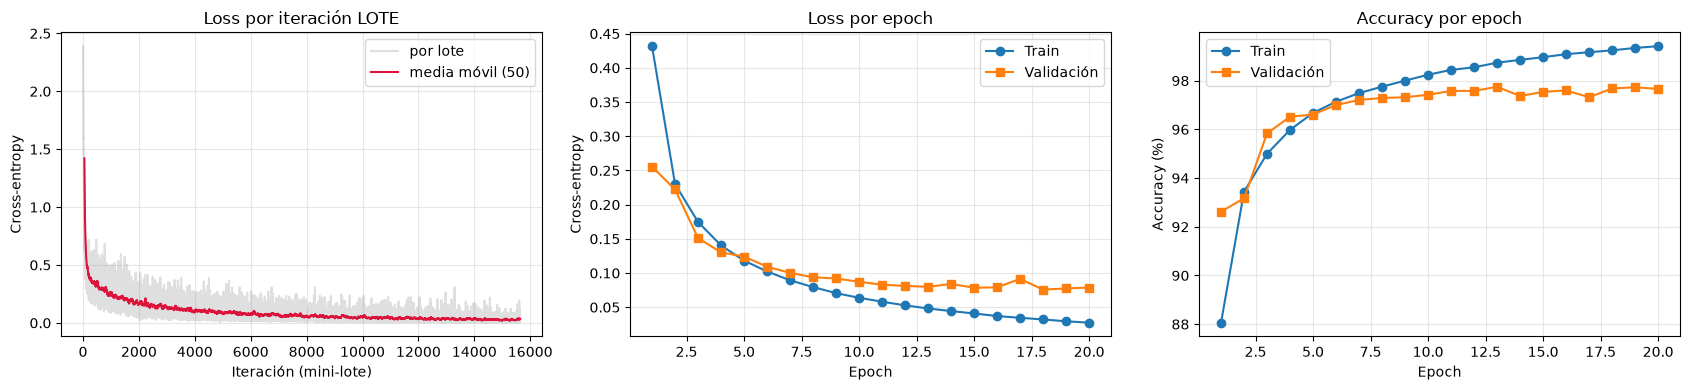

In [16]:
epocas = np.arange(1, epochs + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# Pérdida por mini-lote (suavizada)
suave = np.convolve(loss_por_lote, np.ones(50) / 50, mode="valid")
ax[0].plot(loss_por_lote, alpha=0.25, color="gray", label="por lote")
ax[0].plot(np.arange(len(suave)) + 49, suave, color="crimson", label="media móvil (50)")
ax[0].set_title("Loss por iteración LOTE"); ax[0].set_xlabel("Iteración (mini-lote)"); ax[0].set_ylabel("Cross-entropy")
ax[0].legend()

ax[1].plot(epocas, historial["train_loss"], "o-", label="Train")
ax[1].plot(epocas, historial["val_loss"], "s-", label="Validación")
ax[1].set_title("Loss por epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Cross-entropy"); ax[1].legend()

ax[2].plot(epocas, np.array(historial["train_acc"]) * 100, "o-", label="Train")
ax[2].plot(epocas, np.array(historial["val_acc"]) * 100, "s-", label="Validación")
ax[2].set_title("Accuracy por epoch"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Accuracy (%)"); ax[2].legend()

for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Qué se ve:** la pérdida baja de forma sostenida y el accuracy de validación llega a ~97–98 %, así que la red aprende de verdad. Además, train (~99 %) queda por encima de validación (~97.7 %): hay un **leve sobreajuste** (la red empieza a memorizar parte del train). Es esperable en una red sin regularización y es una buena razón para no entrenar muchos más epochs.

## 4.2 Resultado final en el set de test

Esta es la primera vez que la red ve las 10.000 imágenes de test: es la medida honesta de qué tan bien generaliza.

In [17]:
test_loss, test_acc = evaluar(red, X_test, y_test)
print(f"Accuracy en test: {test_acc*100:.2f}%")
print(f"Loss en test:     {test_loss:.4f}")

probs_test = red.forward(X_test)
y_pred = np.argmax(probs_test, axis=1)
confianza = probs_test.max(axis=1)
print(f"Imágenes mal clasificadas: {np.sum(y_pred != y_test)} de {len(y_test)}")

Accuracy en test: 97.79%
Loss en test:     0.0710
Imágenes mal clasificadas: 221 de 10000


## 4.3 Análisis de errores

**Matriz de confusión:** la fila es el dígito real y la columna lo que predijo la red. La diagonal son los aciertos; lo que está fuera de la diagonal son confusiones.

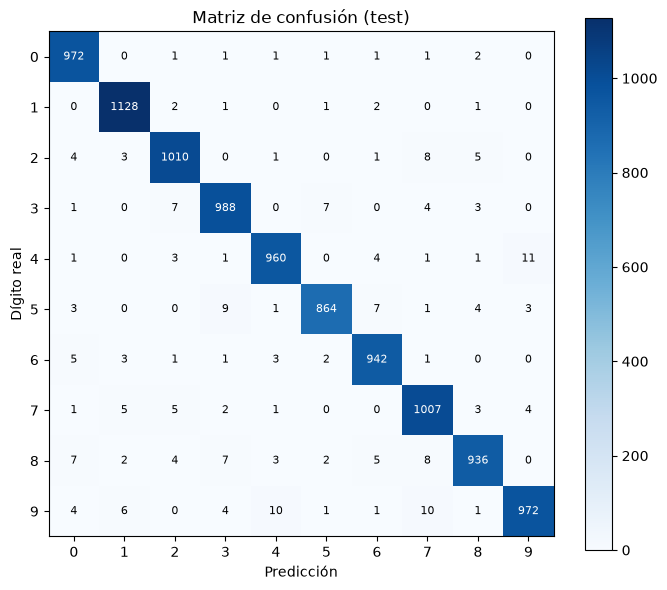

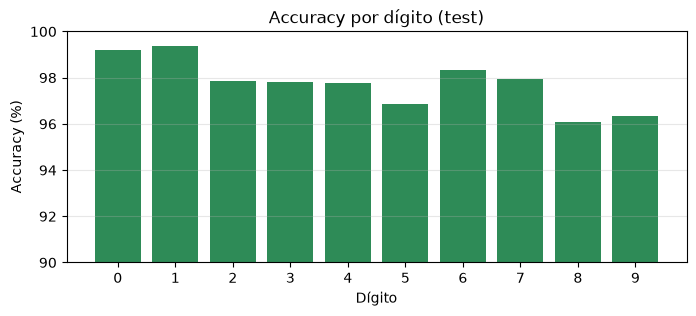

Confusiones más frecuentes (real -> predicho):
   4 confundido con 9: 11 veces
   9 confundido con 7: 10 veces
   9 confundido con 4: 10 veces
   5 confundido con 3: 9 veces
   8 confundido con 7: 8 veces
   2 confundido con 7: 8 veces

Dígito más difícil: 8 (96.10%)
Dígito más fácil:   1 (99.38%)


In [18]:
# Matriz de confusión a mano
matriz = np.zeros((10, 10), dtype=int)
for real, pred in zip(y_test, y_pred):
    matriz[real, pred] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(matriz, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, matriz[i, j], ha="center", va="center",
                color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=8)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Predicción"); ax.set_ylabel("Dígito real")
ax.set_title("Matriz de confusión (test)")
plt.colorbar(im); plt.tight_layout(); plt.show()

# Accuracy por dígito
acc_por_clase = matriz.diagonal() / matriz.sum(axis=1)
plt.figure(figsize=(8, 3))
plt.bar(range(10), acc_por_clase * 100, color="seagreen")
plt.ylim(90, 100); plt.xticks(range(10))
plt.xlabel("Dígito"); plt.ylabel("Accuracy (%)"); plt.title("Accuracy por dígito (test)")
plt.grid(axis="y", alpha=0.3); plt.show()

# Confusiones más frecuentes
sin_diagonal = matriz.copy(); np.fill_diagonal(sin_diagonal, 0)
pares = sorted([(sin_diagonal[i, j], i, j) for i in range(10) for j in range(10)], reverse=True)[:6]
print("Confusiones más frecuentes (real -> predicho):")
for cantidad, real, pred in pares:
    print(f"   {real} confundido con {pred}: {cantidad} veces")
print(f"\nDígito más difícil: {np.argmin(acc_por_clase)} ({acc_por_clase.min()*100:.2f}%)")
print(f"Dígito más fácil:   {np.argmax(acc_por_clase)} ({acc_por_clase.max()*100:.2f}%)")

### Ejemplos de predicciones

Primero aciertos al azar y luego errores. Debajo de cada imagen: `real → predicho (confianza)`.

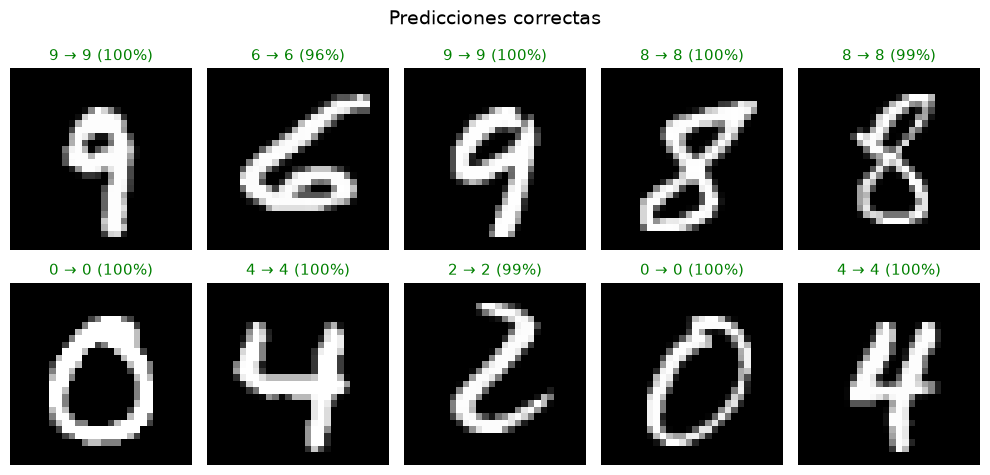

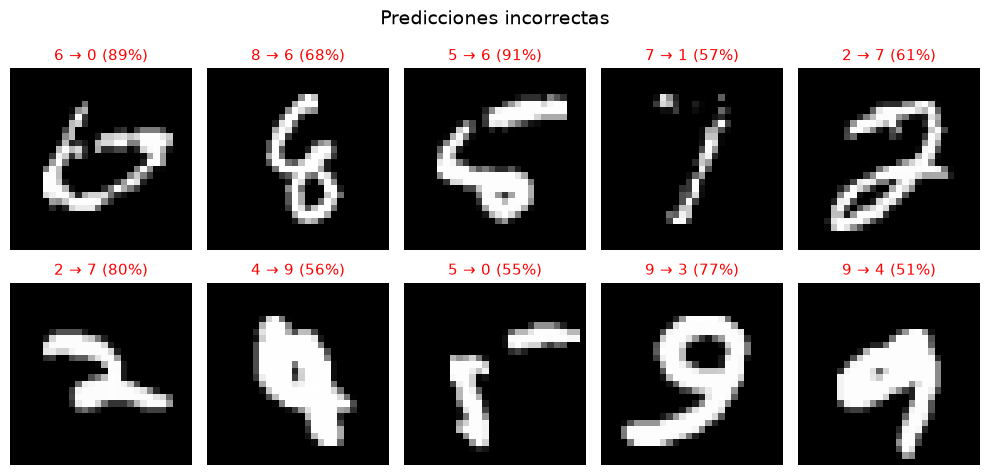

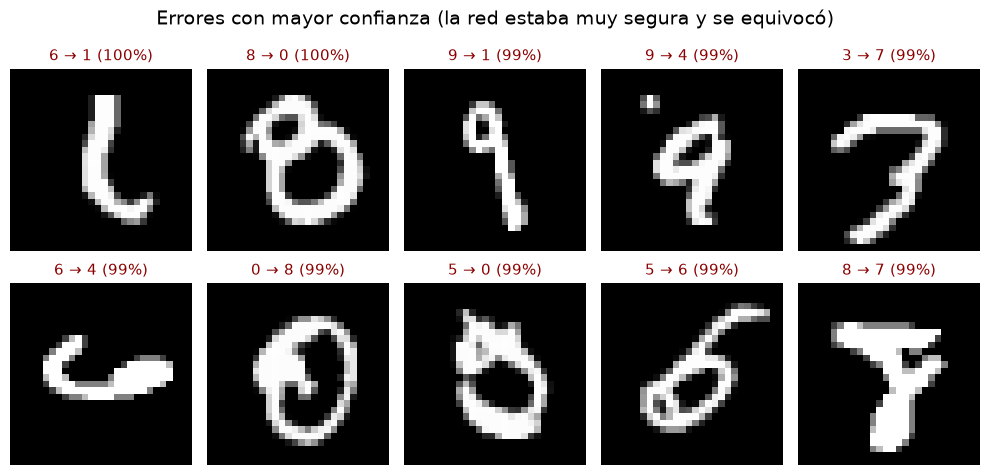

In [19]:
def mostrar_ejemplos(indices, titulo, color):
    fig, axes = plt.subplots(2, 5, figsize=(10, 5))
    for ax, i in zip(axes.flat, indices):
        ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
        ax.set_title(f"{y_test[i]} → {y_pred[i]} ({confianza[i]*100:.0f}%)", color=color, fontsize=11)
        ax.axis("off")
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
correctos = np.where(y_pred == y_test)[0]
errores = np.where(y_pred != y_test)[0]

mostrar_ejemplos(rng.choice(correctos, 10, replace=False), "Predicciones correctas", "green")
mostrar_ejemplos(rng.choice(errores, 10, replace=False), "Predicciones incorrectas", "red")

# Los errores en los que la red estaba MÁS segura
peores = errores[np.argsort(-confianza[errores])[:10]]
mostrar_ejemplos(peores, "Errores con mayor confianza (la red estaba muy segura y se equivocó)", "darkred")

### ¿Por qué se equivoca la red?


- **Las confusiones más frecuentes ocurren entre dígitos que comparten trazos**: `4↔9` (ambos tienen un palo vertical y un lazo/ángulo arriba), `5→3`, `9→7`, `8→7`, `2→7`.
- **El dígito más fácil es el `1`** (~99.4 %): es una sola raya, casi no se parece a nada más. **El más difícil es el `8`** (~96 %): tiene dos lazos y, mal cerrado, se parece a `3`, `5`, `9` o `7`.
- Esta red es un **perceptrón multicapa**: ve la imagen como 784 números sueltos y **no sabe que píxeles vecinos están relacionados**. Un trazo inclinado o corrido cambia muchos píxeles a la vez y la red no puede "darse cuenta" de que sigue siendo el mismo dígito. Por eso las redes convolucionales (CNN) rinden mejor en imágenes.
- Muchos errores con alta confianza son dígitos **mal escritos o ambiguos**, donde incluso una persona dudaría.

## 4.4 Bonus: ¿qué aprendió la primera capa?

Cada una de las 128 neuronas de la capa oculta tiene 784 pesos, uno por píxel. Si los reacomodamos como imagen de 28×28, vemos **qué patrón de píxeles** busca cada neurona (rojo = activa la neurona, azul = la inhibe). Se nota ruido de fondo (viene de la inicialización aleatoria, que el entrenamiento no borra por completo), pero en el centro de la imagen aparecen patrones de trazos: bordes, curvas y líneas que la red encontró útiles.

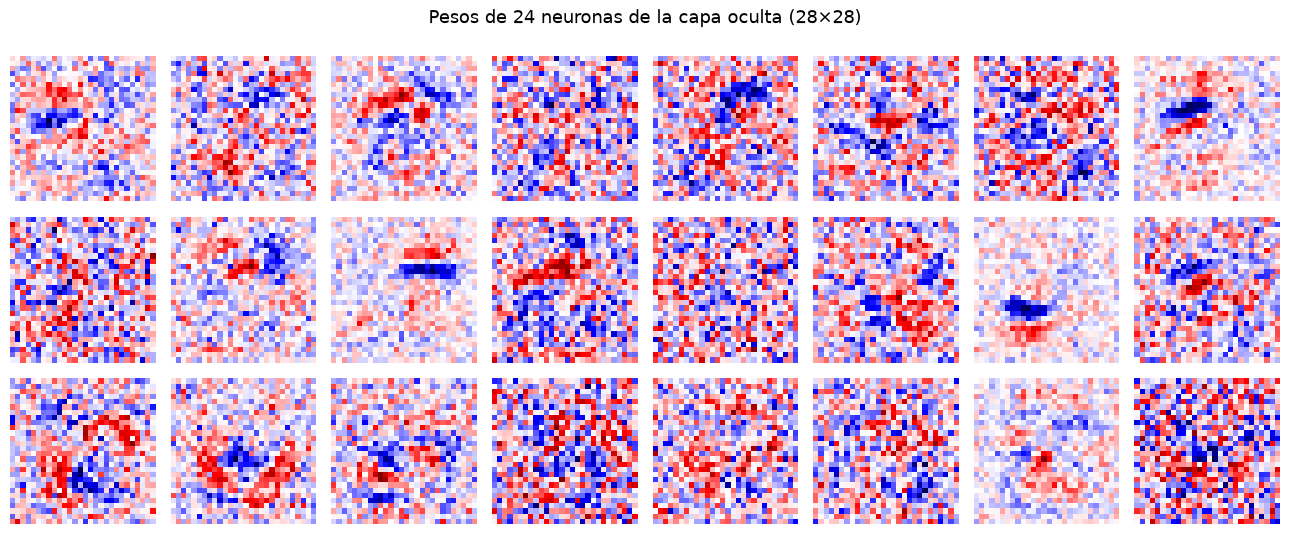

In [20]:
fig, axes = plt.subplots(3, 8, figsize=(13, 5.5))
for k, ax in enumerate(axes.flat):
    w = red.dense1.W[:, k].reshape(28, 28)
    lim = np.abs(w).max()
    ax.imshow(w, cmap="seismic", vmin=-lim, vmax=lim)
    ax.axis("off")
plt.suptitle("Pesos de 24 neuronas de la capa oculta (28×28)", fontsize=13)
plt.tight_layout(); plt.show()

# 5. Conclusiones: ¿Qué entendí que antes no entendía?

*(Borrador: reescribilo con tus propias palabras y tus números finales antes de presentar.)*

**1. Una red neuronal son multiplicaciones de matrices y derivadas.** Mi red completa son dos productos de matrices (`XW + b`), una compuerta (`ReLU`) y una normalización (`Softmax`). No hay nada más. Todo el "aprendizaje" es mover esos pesos poco a poco.

**2. Backpropagation es la regla de la cadena aplicada de atrás hacia adelante.** Cada capa recibe "cuánto le importa a la pérdida mi salida" (`dZ`) y devuelve dos cosas: el gradiente de sus propios pesos (`dW`, `db`) y el gradiente para la capa anterior (`dX`). Entendí por qué hay que **guardar** las entradas en el forward, y por qué las shapes obligan a las transposiciones.

**3. Softmax + Cross-Entropy dan un gradiente muy simple: `P − Y`.** Es "lo que predije menos lo que debía ser". Esa es la señal que arranca todo el backprop.

**4. Los detalles numéricos importan.** Sin restar el máximo en Softmax, aparecen `NaN`. Sin una buena inicialización, la red arranca mal. Y un gradiente mal calculado **no da error, solo no aprende**: por eso el *gradient checking* fue clave para confiar en mi implementación.

**5. Una pérdida de ≈ 2.30 es el "grado cero" del aprendizaje** (`ln 10`: adivinar al azar entre 10 clases). Si la pérdida no se mueve de ahí, algo está roto. Ver la curva bajar fue la prueba de que la red aprende de verdad.

**6. `.fit()` ya no es magia.** Es el loop que escribí: mezclar → forward → loss → backward → update, repetido por epochs. Los frameworks hacen exactamente esto, pero calculando el backward automáticamente (autograd) y en GPU.

**7. Límites de esta red.** Alcanza ~97–98 % en test, pero trata cada píxel de forma independiente. Para mejorar de verdad harían falta capas convolucionales, que aprovechan la estructura espacial de la imagen.